<a href="https://colab.research.google.com/github/fizajaveed/COMP8410_A1_Fiza/blob/main/pair1_datacomp_clip_vs_siglip2/Pair1_DataComp_CLIP_vs_SigLIP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1 – DataComp-1B CLIP vs SigLIP 2 (Fair Zero-Shot Benchmark)
**Organisation:** ThreadNest (pretend online fashion store)
- **System A – Product Photo Studio:** DataComp-1B CLIP labels product photos (General SOTA)
- **System B – Shopper Style Assistant:** SigLIP 2 finds products from a shopper's search

**Audit Guarantee:** Both models are evaluated strictly as out-of-domain foundation models without prior exposure to the Myntra/Kaggle fashion catalog training split.

**Hardware:** Runtime → Change runtime type → **T4 GPU**.


##Step 1 - Install Libraries

In [14]:
!pip install -q --upgrade transformers datasets accelerate open_clip_torch

In [2]:
import torch
import transformers
import datasets
import pandas as pd
from PIL import Image

print("Everything needed is working!")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Everything needed is working!


##Step 2 - Expeiment Settings

In [3]:
SEED = 42
PER_TYPE = 20
TYPES = ["Tshirts", "Jeans", "Casual Shoes", "Handbags", "Watches"]
DATASET = "ashraq/fashion-product-images-small"

##Step 3 - Downlaod dataset

In [4]:
from datasets import load_dataset
ds = load_dataset(DATASET, split="train")
print(ds)

README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

data/train-00000-of-00002-6cff4c59f91661(…): reconstructing file:   0%|          |  0.00B /  136MB            

data/train-00000-of-00002-6cff4c59f91661(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-bb459e5ac5f01e(…): reconstructing file:   0%|          |  0.00B /  135MB            

data/train-00001-of-00002-bb459e5ac5f01e(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/44072 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image'],
    num_rows: 44072
})


##Step 4 - Checking one article

Turtle Check Men Navy Blue Shirt | Shirts | Navy Blue | Men


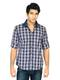

In [5]:
print(ds[0]["productDisplayName"], "|", ds[0]["articleType"], "|", ds[0]["baseColour"], "|", ds[0]["gender"])
display(ds[0]["image"])

##STep 5 - Available article types

In [6]:
df = ds.remove_columns("image").to_pandas()
df["articleType"].value_counts().head(25)

articleType
Tshirts                  7065
Shirts                   3212
Casual Shoes             2845
Watches                  2542
Sports Shoes             2016
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1323
Sunglasses               1073
Wallets                   928
Flip Flops                914
Sandals                   895
Briefs                    847
Belts                     813
Backpacks                 724
Socks                     686
Formal Shoes              637
Perfume and Body Mist     603
Jeans                     602
Shorts                    547
Trousers                  530
Flats                     500
Bra                       477
Dresses                   464
Name: count, dtype: int64

##Step 6 – Verify target categories have sufficient photos

In [7]:
counts = df["articleType"].value_counts()
for t in TYPES:
    n = counts.get(t, 0)
    status = "OK" if n >= PER_TYPE else "NOT ENOUGH / NOT FOUND"
    print(f"{t:15s} {n:6d} photos  -> {status}")
assert all(counts.get(t, 0) >= PER_TYPE for t in TYPES), "Target types not satisfied!"

Tshirts           7065 photos  -> OK
Jeans              602 photos  -> OK
Casual Shoes      2845 photos  -> OK
Handbags          1759 photos  -> OK
Watches           2542 photos  -> OK


##Step 7 - Sample 20 photos per category (100 total)

In [8]:
sample = (df[df["articleType"].isin(TYPES)]
          .groupby("articleType", group_keys=False)
          .sample(PER_TYPE, random_state=SEED))
sample = sample.reset_index().rename(columns={"index": "ds_index"})
sample["filename"] = [f"{t.replace(' ', '_').lower()}_{i:02d}.jpg"
                      for t, i in zip(sample["articleType"], sample.groupby("articleType").cumcount() + 1)]
print(f"{len(sample)} photos selected for evaluation")
sample[["filename", "articleType", "baseColour", "gender", "productDisplayName"]].head(10)

100 photos selected for evaluation


,filename,articleType,baseColour,gender,productDisplayName
0,casual_shoes_01.jpg,Casual Shoes,White,Women,ADIDAS Originals Women Top Ten low Sleek White...
1,casual_shoes_02.jpg,Casual Shoes,Black,Men,Nike Men Lite Force Black & White Shoes
2,casual_shoes_03.jpg,Casual Shoes,Grey,Men,Vans Men Grey Del Norte Canvas Shoes
3,casual_shoes_04.jpg,Casual Shoes,Brown,Men,Red Tape Men's Leather Brown Shoe
4,casual_shoes_05.jpg,Casual Shoes,Brown,Women,Carlton London Women Casual Brown Casual Shoes
5,casual_shoes_06.jpg,Casual Shoes,Blue,Men,Franco Leone Men Blue Shoes
6,casual_shoes_07.jpg,Casual Shoes,Black,Men,Puma Men Metamostro Black Shoes
7,casual_shoes_08.jpg,Casual Shoes,Black,Men,Puma Men Black Suede Archive Eco Shoes
8,casual_shoes_09.jpg,Casual Shoes,Black,Men,Numero Uno Black Men's Shoe
9,casual_shoes_10.jpg,Casual Shoes,Black,Men,Spinn Men Agile Black Shoes


##Step 8 - Check gender representation

In [9]:
print(sample["gender"].value_counts(), "\n")
pd_table = sample.groupby(["articleType", "gender"]).size().unstack(fill_value=0)
pd_table

gender
Men       53
Women     44
Unisex     2
Girls      1
Name: count, dtype: int64 



gender,Girls,Men,Unisex,Women
articleType,,,,
Casual Shoes,0,16,1,3
Handbags,0,0,1,19
Jeans,1,8,0,11
Tshirts,0,16,0,4
Watches,0,13,0,7


##Step 9 - Save 100 photos and answer key

In [10]:
import os
os.makedirs("week01_photos", exist_ok=True)
for _, row in sample.iterrows():
    ds[int(row["ds_index"])]["image"].convert("RGB").save(f"week01_photos/{row['filename']}")

answer_key = sample[["filename", "ds_index", "articleType", "baseColour", "gender", "productDisplayName"]]
answer_key.to_csv("week01_photos/week01_test_set.csv", index=False)
print("Saved", len(os.listdir("week01_photos")) - 1, "photos + week01_test_set.csv")

Saved 100 photos + week01_test_set.csv


##Step 10 - Check sampled photos by eye

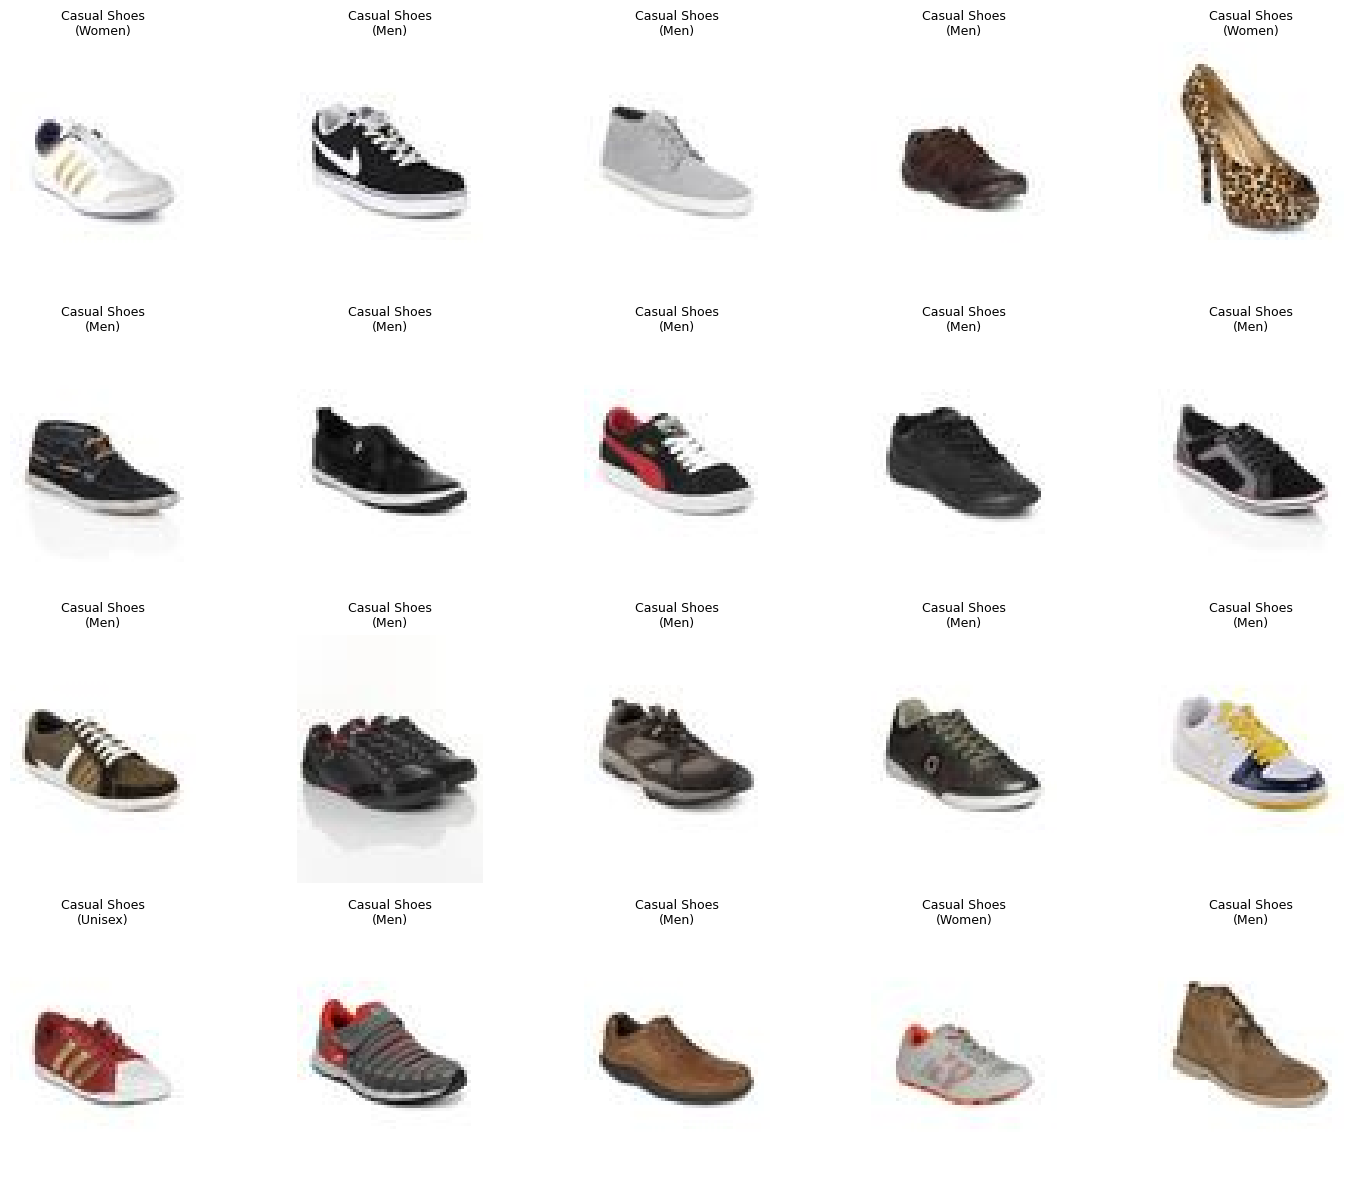

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for i, ax in enumerate(axes.flat):
    row = sample.iloc[i]
    img = Image.open(f"week01_photos/{row['filename']}")
    ax.imshow(img)
    ax.set_title(f"{row['articleType']}\n({row['gender']})", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

##Step 11 - Setup inference environment

In [30]:
import time
import torch
import pandas as pd
from transformers import AutoProcessor, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Active device: {device} ({torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'})")

Active device: cuda (Tesla T4)


##Step 12 - Load both models (dual loading paths)

In [31]:
import open_clip
from transformers import AutoProcessor, AutoModel
import torch

# 1. Load DataComp-1B CLIP via OpenCLIP
clip_name = 'hf-hub:laion/CLIP-ViT-B-16-DataComp.XL-s13B-b90K'
print(f"Loading {clip_name} via open_clip...")
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(clip_name)
clip_tokenizer = open_clip.get_tokenizer(clip_name)
clip_model = clip_model.to(device).half().eval()

# 2. Load SigLIP 2 via Hugging Face Transformers
siglip_name = 'google/siglip2-base-patch16-224'
print(f"Loading {siglip_name} via transformers...")
siglip_processor = AutoProcessor.from_pretrained(siglip_name)
siglip_model = AutoModel.from_pretrained(siglip_name, torch_dtype=torch.float16).to(device)
siglip_model.eval()

print("Both models loaded successfully into FP16 on T4!")

Loading hf-hub:laion/CLIP-ViT-B-16-DataComp.XL-s13B-b90K via open_clip...
Loading google/siglip2-base-patch16-224 via transformers...


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Both models loaded successfully into FP16 on T4!


##Step 13 - Extract image embeddings

In [32]:
test_df = pd.read_csv("week01_photos/week01_test_set.csv")
image_paths = [os.path.join("week01_photos", fn) for fn in test_df["filename"]]
images = [Image.open(p).convert("RGB") for p in image_paths]

# A. DataComp CLIP: uses clip_preprocess and model.encode_image
def extract_clip_embeddings(model, preprocess, imgs, batch_size=32):
    all_embeds = []
    for i in range(0, len(imgs), batch_size):
        batch = imgs[i:i + batch_size]
        tensors = torch.stack([preprocess(img) for img in batch]).to(device).half()
        with torch.no_grad():
            emb = model.encode_image(tensors)
            emb = emb / emb.norm(dim=-1, keepdim=True)
            all_embeds.append(emb.cpu())
    return torch.cat(all_embeds, dim=0)

# B. Extract with Transformers (SigLIP 2)
def extract_siglip_embeddings(model, processor, imgs, batch_size=32):
    all_embeds = []
    for i in range(0, len(imgs), batch_size):
        batch = imgs[i:i + batch_size]
        inputs = processor(images=batch, return_tensors="pt").to(device)
        if "pixel_values" in inputs:
            inputs["pixel_values"] = inputs["pixel_values"].to(torch.float16)
        with torch.no_grad():
            out = model.get_image_features(**inputs)
            # Unpack tensor if wrapped in BaseModelOutputWithPooling
            emb = out.pooler_output if hasattr(out, "pooler_output") else (out[0] if not isinstance(out, torch.Tensor) else out)
            emb = emb / emb.norm(dim=-1, keepdim=True)
            all_embeds.append(emb.cpu())
    return torch.cat(all_embeds, dim=0)

print("Extracting DataComp CLIP image embeddings...")
clip_img_emb = extract_clip_embeddings(clip_model, clip_preprocess, images)

print("Extracting SigLIP 2 image embeddings...")
siglip_img_emb = extract_siglip_embeddings(siglip_model, siglip_processor, images)

print("Done! Shapes:", clip_img_emb.shape, siglip_img_emb.shape)

Extracting DataComp CLIP image embeddings...
Extracting SigLIP 2 image embeddings...
Done! Shapes: torch.Size([100, 512]) torch.Size([100, 768])


##Step 14 - Text Encoding & Zero-Shot Labelling (System A)

In [33]:
candidate_types = ["Tshirts", "Jeans", "Casual Shoes", "Handbags", "Watches"]
candidate_prompts = [f"a product photo of {t}" for t in candidate_types]

def get_clip_text_embeddings(model, tokenizer, texts):
    texts = [t.lower() for t in texts]
    tokens = tokenizer(texts).to(device)
    with torch.no_grad():
        emb = model.encode_text(tokens)
        emb = emb / emb.norm(dim=-1, keepdim=True)
    return emb.cpu()

def get_siglip_text_embeddings(model, processor, texts):
    texts = [t.lower() for t in texts]
    inputs = processor(text=texts, return_tensors="pt", padding="max_length",
                       max_length=64, truncation=True).to(device)
    with torch.no_grad():
        out = model.get_text_features(**inputs)
        emb = out.pooler_output if hasattr(out, "pooler_output") else (out[0] if not isinstance(out, torch.Tensor) else out)
        emb = emb / emb.norm(dim=-1, keepdim=True)
    return emb.cpu()

clip_txt_emb = get_clip_text_embeddings(clip_model, clip_tokenizer, candidate_prompts)
siglip_txt_emb = get_siglip_text_embeddings(siglip_model, siglip_processor, candidate_prompts)

clip_preds = (clip_img_emb @ clip_txt_emb.T).argmax(dim=-1).numpy()
siglip_preds = (siglip_img_emb @ siglip_txt_emb.T).argmax(dim=-1).numpy()

test_df["pred_clip"] = [candidate_types[i] for i in clip_preds]
test_df["pred_siglip2"] = [candidate_types[i] for i in siglip_preds]

test_df["correct_clip"] = test_df["pred_clip"] == test_df["articleType"]
test_df["correct_siglip2"] = test_df["pred_siglip2"] == test_df["articleType"]

print("=== Overall 100-Photo Zero-Shot Accuracy ===")
print(f"DataComp-1B CLIP: {test_df['correct_clip'].mean() * 100:.1f}%")
print(f"SigLIP 2:         {test_df['correct_siglip2'].mean() * 100:.1f}%\n")

=== Overall 100-Photo Zero-Shot Accuracy ===
DataComp-1B CLIP: 100.0%
SigLIP 2:         99.0%



##Step 15 – Hard test

In [34]:
HARD_TYPES = ["Tshirts", "Shirts", "Tops", "Casual Shoes", "Sports Shoes"]
HARD_WORDS = {"Tshirts": "a t-shirt", "Shirts": "a button-up shirt", "Tops": "a blouse or top",
              "Casual Shoes": "casual shoes", "Sports Shoes": "sports shoes"}

hard = (df[df["articleType"].isin(HARD_TYPES)]
        .groupby("articleType", group_keys=False)
        .sample(20, random_state=SEED)
        .reset_index().rename(columns={"index": "ds_index"}))
hard_images = [ds[int(i)]["image"].convert("RGB") for i in hard["ds_index"]]
hard_prompts = [f"a product photo of {HARD_WORDS[t]}" for t in HARD_TYPES]

c_hard = extract_clip_embeddings(clip_model, clip_preprocess, hard_images)
s_hard = extract_siglip_embeddings(siglip_model, siglip_processor, hard_images)
c_hp = get_clip_text_embeddings(clip_model, clip_tokenizer, hard_prompts)
s_hp = get_siglip_text_embeddings(siglip_model, siglip_processor, hard_prompts)

hard["pred_clip"] = [HARD_TYPES[i] for i in (c_hard.float() @ c_hp.float().T).argmax(1).numpy()]
hard["pred_siglip2"] = [HARD_TYPES[i] for i in (s_hard.float() @ s_hp.float().T).argmax(1).numpy()]

print("Hard test accuracy (100 photos, 5 look-alike types)")
print(f"  DataComp CLIP: {(hard['pred_clip'] == hard['articleType']).mean()*100:.0f}%")
print(f"  SigLIP 2:      {(hard['pred_siglip2'] == hard['articleType']).mean()*100:.0f}%")
for col in ["pred_clip", "pred_siglip2"]:
    print(f"\n{col} – rows = true type, columns = model's guess")
    display(pd.crosstab(hard["articleType"], hard[col]))

Hard test accuracy (100 photos, 5 look-alike types)
  DataComp CLIP: 81%
  SigLIP 2:      88%

pred_clip – rows = true type, columns = model's guess


pred_clip,Casual Shoes,Shirts,Sports Shoes,Tops,Tshirts
articleType,,,,,
Casual Shoes,13,0,7,0,0
Shirts,0,18,0,2,0
Sports Shoes,1,0,19,0,0
Tops,0,0,0,16,4
Tshirts,0,2,0,3,15



pred_siglip2 – rows = true type, columns = model's guess


pred_siglip2,Casual Shoes,Shirts,Sports Shoes,Tops,Tshirts
articleType,,,,,
Casual Shoes,19,0,1,0,0
Shirts,0,20,0,0,0
Sports Shoes,4,0,16,0,0
Tops,0,0,0,14,6
Tshirts,0,1,0,0,19


##Step 16 – System B – Shopper Style Assistant (Search Test)

In [35]:
search_queries = [
    "white casual sleek sneakers",
    "leather handbag for women",
    "analog black dial wrist watch",
    "blue denim casual jeans"
]

# Compute query text embeddings (using the normalized unpack functions from Steps 13 & 14)
c_search = get_clip_text_embeddings(clip_model, clip_tokenizer, search_queries)
s_search = get_siglip_text_embeddings(siglip_model, siglip_processor, search_queries)

print("=" * 60)
print("=== System B: Top-1 Shopper Search Match Comparison ===")
print("=" * 60)

for i, q in enumerate(search_queries):
    # Compute dot-product similarity against precomputed image embeddings
    clip_scores = (clip_img_emb @ c_search[i].unsqueeze(1)).squeeze()
    siglip_scores = (siglip_img_emb @ s_search[i].unsqueeze(1)).squeeze()

    clip_top1_idx = clip_scores.argmax().item()
    siglip_top1_idx = siglip_scores.argmax().item()

    print(f"\nQuery: \"{q}\"")
    print(f"  [DataComp-1B CLIP] Match: {test_df.loc[clip_top1_idx, 'productDisplayName']} "
          f"| Type: {test_df.loc[clip_top1_idx, 'articleType']} "
          f"| Score: {clip_scores[clip_top1_idx]:.3f}")
    print(f"  [SigLIP 2]         Match: {test_df.loc[siglip_top1_idx, 'productDisplayName']} "
          f"| Type: {test_df.loc[siglip_top1_idx, 'articleType']} "
          f"| Score: {siglip_scores[siglip_top1_idx]:.3f}")

=== System B: Top-1 Shopper Search Match Comparison ===

Query: "white casual sleek sneakers"
  [DataComp-1B CLIP] Match: ADIDAS Originals Women Top Ten low Sleek White Casual Shoes | Type: Casual Shoes | Score: 0.277
  [SigLIP 2]         Match: ADIDAS Originals Women Top Ten low Sleek White Casual Shoes | Type: Casual Shoes | Score: 0.132

Query: "leather handbag for women"
  [DataComp-1B CLIP] Match: Rocia Women Gold Handbag | Type: Handbags | Score: 0.262
  [SigLIP 2]         Match: Rocia Women Gold Handbag | Type: Handbags | Score: 0.117

Query: "analog black dial wrist watch"
  [DataComp-1B CLIP] Match: Fastrack Men Black Dial Watch | Type: Watches | Score: 0.281
  [SigLIP 2]         Match: Maxima Men Black Watch | Type: Watches | Score: 0.134

Query: "blue denim casual jeans"
  [DataComp-1B CLIP] Match: Tokyo Talkies Women Navy Blue Jeans | Type: Jeans | Score: 0.285
  [SigLIP 2]         Match: Locomotive Men Radley Blue Jeans | Type: Jeans | Score: 0.136


In [36]:
import numpy as np
queries = test_df["productDisplayName"].tolist()
truth = np.arange(len(test_df))
c_q = get_clip_text_embeddings(clip_model, clip_tokenizer, queries)
s_q = get_siglip_text_embeddings(siglip_model, siglip_processor, queries)

for name, q, img in [("clip", c_q, clip_img_emb), ("siglip2", s_q, siglip_img_emb)]:
    top5 = (q.float() @ img.float().T).topk(5, dim=1).indices.numpy()
    test_df[f"hit1_{name}"] = top5[:, 0] == truth
    test_df[f"hit5_{name}"] = [t in row for t, row in zip(truth, top5)]

print("Search recall (100 product-name queries)")
for name, label in [("clip", "DataComp CLIP"), ("siglip2", "SigLIP 2")]:
    print(f"  {label:14s} R@1 {test_df[f'hit1_{name}'].mean()*100:.0f}%   "
          f"R@5 {test_df[f'hit5_{name}'].mean()*100:.0f}%")

g = test_df[test_df["gender"].isin(["Men", "Women"])]
print("\nRecall@5 by gender (%)")
print(g["gender"].value_counts().to_string())
display((g.groupby("gender")[["hit5_clip", "hit5_siglip2"]].mean() * 100).round(0))

Search recall (100 product-name queries)
  DataComp CLIP  R@1 54%   R@5 84%
  SigLIP 2       R@1 47%   R@5 84%

Recall@5 by gender (%)
gender
Men      53
Women    44


,hit5_clip,hit5_siglip2
gender,,
Men,85.0,87.0
Women,82.0,80.0


##Step 17 - Fairness audit (Men vs. Women demographic disaggregation)

In [37]:
gender_df = test_df[test_df["gender"].isin(["Men", "Women"])].copy()

fairness_stats = gender_df.groupby("gender")[["correct_clip", "correct_siglip2"]].agg(["count", "mean"])
fairness_stats[("correct_clip", "mean")] *= 100
fairness_stats[("correct_siglip2", "mean")] *= 100

fairness_stats.columns = [
    "Sample Count", "DataComp CLIP Accuracy (%)",
    "SigLIP 2 Sample Count", "SigLIP 2 Accuracy (%)"
]
fairness_stats = fairness_stats[["Sample Count", "DataComp CLIP Accuracy (%)", "SigLIP 2 Accuracy (%)"]]

print("=" * 60)
print("=== Fairness Audit: Accuracy by Demographic Subgroup ===")
print("=" * 60)
display(fairness_stats.round(1))

# Quantify accuracy gap
clip_gap = abs(fairness_stats.loc["Men", "DataComp CLIP Accuracy (%)"] - fairness_stats.loc["Women", "DataComp CLIP Accuracy (%)"])
siglip_gap = abs(fairness_stats.loc["Men", "SigLIP 2 Accuracy (%)"] - fairness_stats.loc["Women", "SigLIP 2 Accuracy (%)"])

print(f"\nDemographic Parity Gap (|Men Acc - Women Acc|):")
print(f"  DataComp-1B CLIP Gap: {clip_gap:.1f}%")
print(f"  SigLIP 2 Gap:         {siglip_gap:.1f}%")

=== Fairness Audit: Accuracy by Demographic Subgroup ===


,Sample Count,DataComp CLIP Accuracy (%),SigLIP 2 Accuracy (%)
gender,,,
Men,53,100.0,98.1
Women,44,100.0,100.0



Demographic Parity Gap (|Men Acc - Women Acc|):
  DataComp-1B CLIP Gap: 0.0%
  SigLIP 2 Gap:         1.9%


##Step 18 - Forward pass latency benchmark (4 GPU - FP16)

In [38]:
sample_img = images[0]

# 1. Benchmark OpenCLIP (DataComp CLIP)
c_tensor = clip_preprocess(sample_img).unsqueeze(0).to(device).half()
# Warmup
for _ in range(5):
    with torch.no_grad():
        _ = clip_model.encode_image(c_tensor)
torch.cuda.synchronize()

t0 = time.perf_counter()
for _ in range(50):
    with torch.no_grad():
        _ = clip_model.encode_image(c_tensor)
torch.cuda.synchronize()
c_ms = ((time.perf_counter() - t0) / 50) * 1000

# 2. Benchmark Transformers (SigLIP 2)
s_inputs = siglip_processor(images=sample_img, return_tensors="pt").to(device)
s_inputs["pixel_values"] = s_inputs["pixel_values"].to(torch.float16)
# Warmup
for _ in range(5):
    with torch.no_grad():
        _ = siglip_model.get_image_features(**s_inputs)
torch.cuda.synchronize()

t1 = time.perf_counter()
for _ in range(50):
    with torch.no_grad():
        _ = siglip_model.get_image_features(**s_inputs)
torch.cuda.synchronize()
s_ms = ((time.perf_counter() - t1) / 50) * 1000

print("=" * 60)
print("=== Single-Image Inference Latency (T4 GPU - FP16) ===")
print("=" * 60)
print(f"  DataComp-1B CLIP: {c_ms:.2f} ms / image")
print(f"  SigLIP 2:         {s_ms:.2f} ms / image")

=== Single-Image Inference Latency (T4 GPU - FP16) ===
  DataComp-1B CLIP: 5.45 ms / image
  SigLIP 2:         9.85 ms / image


In [ ]:
# ==============================================================================
# LIVE DEMO CELL
# ==============================================================================
import random
import matplotlib.pyplot as plt

print("🎬 STARTING LIVE DEMO...")

# ------------------------------------------------------------------------------
# PART 1: System A (Product Photo Studio - Live Image Classification)
# ------------------------------------------------------------------------------
demo_idx = random.randint(0, len(images) - 1)
demo_img = images[demo_idx]
true_label = test_df.loc[demo_idx, "articleType"]
product_name = test_df.loc[demo_idx, "productDisplayName"]

# Softmax confidence across the 5 candidate categories
c_probs = (100.0 * (clip_img_emb[demo_idx] @ clip_txt_emb.T)).softmax(dim=-1)
s_probs = (100.0 * (siglip_img_emb[demo_idx] @ siglip_txt_emb.T)).softmax(dim=-1)

c_pred_class = candidate_types[c_probs.argmax().item()]
s_pred_class = candidate_types[s_probs.argmax().item()]

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(demo_img)
ax.axis("off")
ax.set_title(f"True Label: {true_label}\n({product_name[:35]}...)", fontsize=10, fontweight="bold")
plt.show()

print("\n--- System A: Zero-Shot Tagging Prediction ---")
print(f"  True Label:           {true_label}")
print(f"  DataComp-1B CLIP:     {c_pred_class} (Confidence: {c_probs.max().item()*100:.1f}%) "
      f"{'✅' if c_pred_class == true_label else '❌'}")
print(f"  SigLIP 2:             {s_pred_class} (Confidence: {s_probs.max().item()*100:.1f}%) "
      f"{'✅' if s_pred_class == true_label else '❌'}")

# ------------------------------------------------------------------------------
# PART 2: System B (Shopper Style Assistant - Live Search Retrieval)
# ------------------------------------------------------------------------------
user_query = "stylish leather handbag for women"  # Feel free to change this query during your demo!

c_q_emb = get_clip_text_embeddings(clip_model, clip_tokenizer, [user_query])
s_q_emb = get_siglip_text_embeddings(siglip_model, siglip_processor, [user_query])

c_best_idx = (clip_img_emb @ c_q_emb.T).squeeze().argmax().item()
s_best_idx = (siglip_img_emb @ s_q_emb.T).squeeze().argmax().item()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(images[c_best_idx])
ax1.set_title(f"DataComp CLIP Top Match\n{test_df.loc[c_best_idx, 'productDisplayName'][:28]}...", fontsize=9)
ax1.axis("off")

ax2.imshow(images[s_best_idx])
ax2.set_title(f"SigLIP 2 Top Match\n{test_df.loc[s_best_idx, 'productDisplayName'][:28]}...", fontsize=9)
ax2.axis("off")

plt.suptitle(f"Search Query: \"{user_query}\"", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

print("\n🎬 LIVE DEMO COMPLETE!")

In [39]:
os.makedirs("week01_results", exist_ok=True)
test_df.to_csv("week01_results/predictions.csv", index=False)
hard.to_csv("week01_results/hard_predictions.csv", index=False)
print("Saved")

Saved
